TokaMaker Example: Equilibrium reconstruction in DIII-D Using Scrape-Off Layer Currents {#doc_tMaker_DIIID_ex3}
==========
In this example we show how to perform an equilibrium reconstruction in DIII-D using TokaMaker's Scrape-Off Layer Current functionality. This example demonstrates the new reconstruction method, which leverages a multi-step approach where:
 1) An EFIT-like quasi-linear reconstruction is performed by fitting to Mirnov and flux loop constraints during the standard nonlinear solve
 2) The reconstruction is refined using a fully general nonlinear approach that utilizes [scipy.optimize.least_squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html) and thus supports many other optimization methods

This example utilizes the mesh built in \ref doc_tMaker_DIIID_ex1.

**Note:** Running this example requires the [h5py](https://www.h5py.org/) python package, which is installable using `pip` or other standard methods.

**Warning:** The reconstruction functionality in TokaMaker is still a work in progress, as the PSI-Tri capabilities are activated and tested. Scrape-Off Layer Currents are also under development. Please use with care.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where the module is located. This can be done either through the `PYTHONPATH` environment variable or done within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

For meshing we will use the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain "gs_Domain" class to build a 2D triangular grid suitable for Grad-Shafranov equilibria (see \ref doc_tMaker_DIIID_ex1).

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.util import mu0
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import load_gs_mesh
from OpenFUSIONToolkit.TokaMaker.util import read_eqdsk, read_mhdin, read_kfile
from OpenFUSIONToolkit.TokaMaker.reconstruction import reconstruction

## Initialize TokaMaker object
We now create a \ref OpenFUSIONToolkit.OFT_env "OFT_env" instance for execution using two threads and a \ref OpenFUSIONToolkit.TokaMaker.TokaMaker "TokaMaker" instance to use for equilibrium calculations. Note at present only a single `TokaMaker` instance can be used per python kernel, so this command should only be called **once** in a given Jupyter notebook or python script. In the future this restriction may be relaxed.

In [3]:
myOFT = OFT_env(nthreads=2)
mygs = TokaMaker(myOFT)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        v26.6
Development branch:  Add-FSOL
Revision id:         ea58b400

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



## Load Info from gEQDSK File and MHDIn.Dat
Here we load info from a gEQDSK equilibrium file and an mhdin.dat file. The former contains information about the plasma equilibrium we want to model. For a full explanation of the contents of the gEQDSK file, see \ref doc_tMaker_DIIID_ex1 doc_tMaker_DIIID_ex2.

In [4]:
shot_tag = '199377.02500'
# eqdsk = read_eqdsk('g'+shot_tag)
eqdsk  = read_eqdsk('g199377-1.02500')

### Load mesh and mhdin.dat
Now we load the mesh generated in see \ref doc_tMaker_DIIID_ex1 using \ref OpenFUSIONToolkit.TokaMaker.load_gs_mesh "load_gs_mesh()" and \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_mesh "setup_mesh". Then we use \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_regions "setup_regions()", passing the conductor and coil dictionaries for the mesh, to define the different region types. Then, we call \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup "setup()" to setup the required solver objects. During this call we can specify the desired element order (min=2, max=4) and the toroidal field through F0 = B0*R0, where B0 is the toroidal field at a reference location R0 (which we have extracted from the gEQDSK file). Lastly, we load machine information from the mhdin.dat file, which contains information about probes and flux loops in the machine. It can be obtained from the DIII-D group.
Warning: Since different versions of DIII-D are used in different shots, please ensure that you are using the correct mhdin.dat that corresponds to your eqdsk and k file if running a different shot.

In [5]:
mesh_pts,mesh_lc,mesh_reg,coil_dict,cond_dict = load_gs_mesh('DIIID_mesh_199377.h5')
mygs.setup_mesh(mesh_pts, mesh_lc, mesh_reg)
mygs.setup_regions(cond_dict=cond_dict,coil_dict=coil_dict)
mygs.setup(order = 2, F0 = eqdsk['rcentr']*eqdsk['bcentr'])

e_coil_names = ['ECOILA', 'ECOILB', 'E567UP', 'E567DN', 'E89DN', 'E89UP']
f_coil_names = [coil_name for coil_name in coil_dict.keys() if coil_name.startswith('F')]
machine_dict, _ = read_mhdin('mhdin040324.dat', e_coil_names, f_coil_names)


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =    9190
    # of edges   =   27407
    # of cells   =   18218
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  3.159E-04
    hrms =  4.752E-02
    hmax =  1.540E-01
  Surface grounded at vertex    1779


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing flux BC matrix 
 Inverting real matrix
   Time =    2.7409999999999999E-003


### Define vertical stability coils
Like many elongated equilibria, the equilibrium we seek to compute below is vertically unstable. In this case we use the F9A and F9B pair of poloidal field coils for vertical stability in order to help with convergence using the \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_coil_vsc "set_coil_vsc()" method.

In [6]:
vsc_signs = {key: 0 for key in mygs.coil_sets}
vsc_signs['F9A'] = 1.0
vsc_signs['F9B'] = -1.0
mygs.set_coil_vsc(vsc_signs)

### Load Sensor Locations From Files
Here we extract Mirnov probe and flux loop locations and orientations from the dictionary returned by the mhdin.dat file reader. We also plot the sensors so we can see how they are distributed over the reactor.

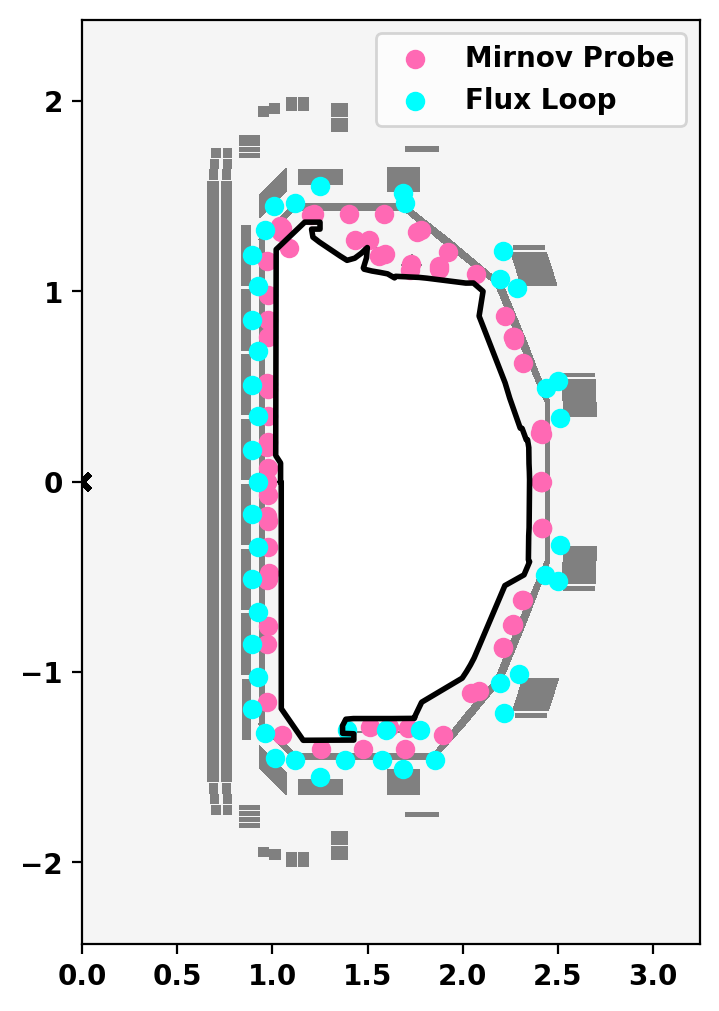

In [7]:
mag_sensors = machine_dict['PROBE']
flux_loops = machine_dict['LOOP']

fig, ax = plt.subplots(1,1)
mygs.plot_machine(fig,ax,limiter_color='k')
mygs.plot_psi(fig,ax,plasma_nlevels=5,vacuum_nlevels=5)
mygs.plot_constraints(fig, ax)

def plot_sensors(sensors, label, color):
    r_coords = [s[0] for _,s in sensors.items()]
    z_coords = [s[1] for _,s in sensors.items()]
    ax.scatter(x=r_coords, y=z_coords, label=label, color=color)

plot_sensors(mag_sensors, label="Mirnov Probe", color='hotpink')
plot_sensors(flux_loops, label="Flux Loop", color='cyan')

ax.legend()
plt.show()

### Load k-file Data from DIII-D
Here we load data from a DIII-D k-file representing a shot at a given point in time. This contains diagnostic measurements of values from the Mirnov probes and flux loops whose locations are stored in `machine_dict`. This is also available from the DIII-D group.

In [8]:
probes_dict, loops_dict, e_coil_dict, f_coil_dict, _ = read_kfile('k'+shot_tag, machine_dict, e_coil_names, f_coil_names)

### FF' and P' Profiles
Here we define profiles for the FF' and P' terms in the Grad-Shafranov equation. The profiles are defined using a combination of experimental profiles from the gEQDSK file and a gaussian test function located in the SOL region. The gaussian shape was inspired by real SOL data from a shot that is not publicly available.

Toggle the `f_SOL` flag to turn SOL currents on and off.

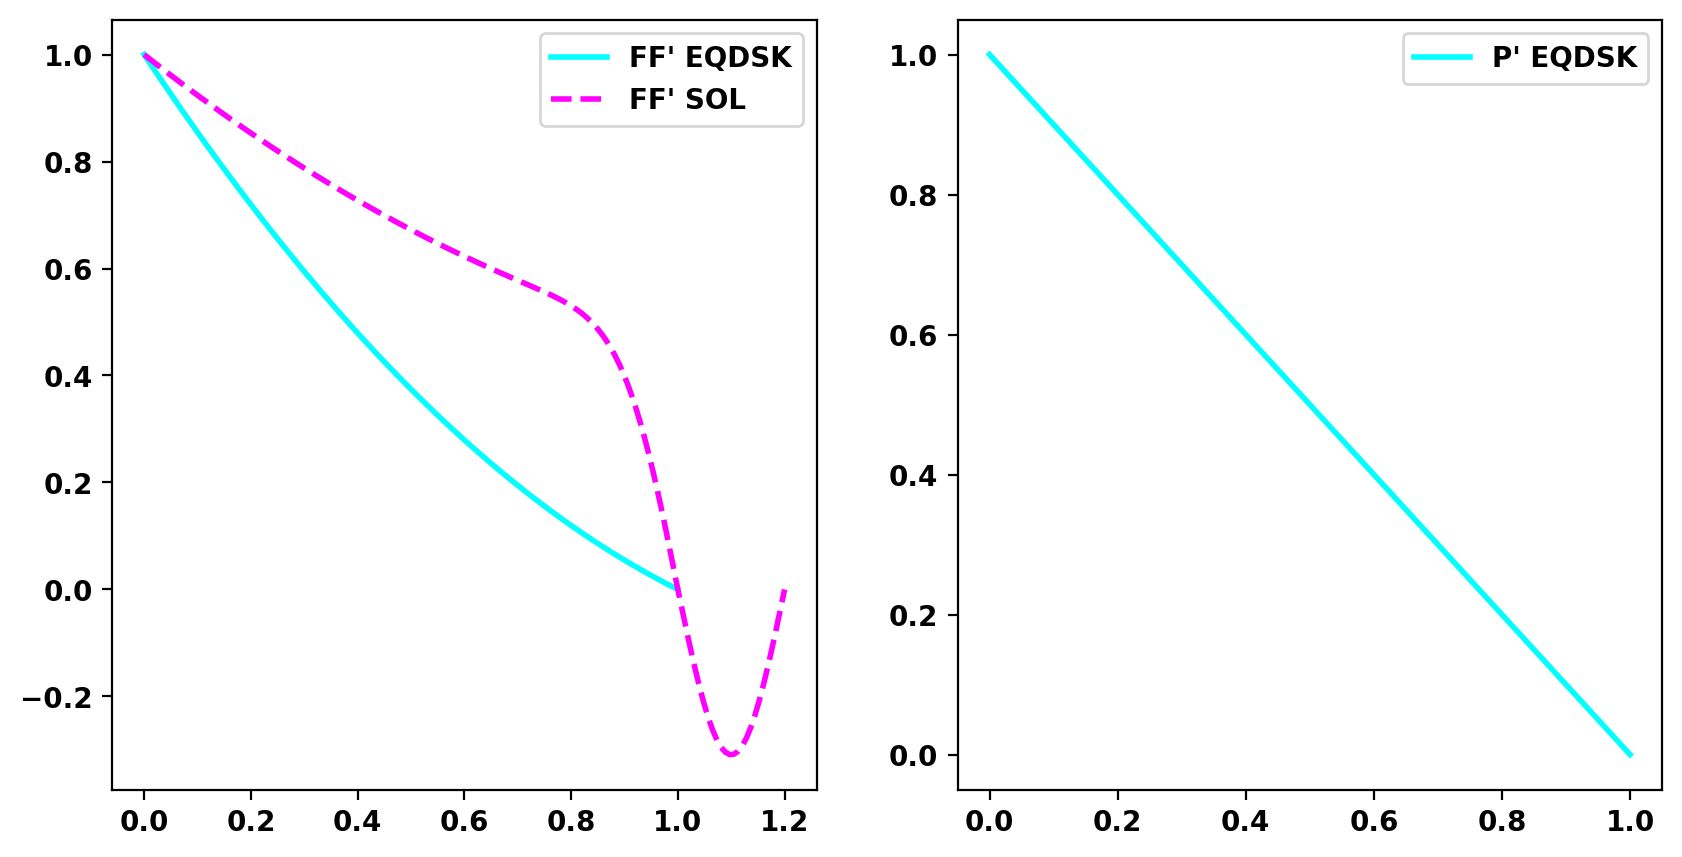

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10,5))
ffprim = eqdsk['ffprim']
pprime = eqdsk['pprime']

ffprim -= ffprim[-1]
ffprim = ffprim / ffprim[0]

pprime -= pprime[-1]
pprime = pprime / pprime[0]

x = np.linspace(0.0, 1.0, len(ffprim))

ax[0].plot(x, ffprim, label='FF\' EQDSK', color='cyan')
ax[1].plot(x, pprime, label='P\' EQDSK', color='cyan')

f_SOL = False
if f_SOL:
    x_sol = np.linspace(1.01, 1.2, 25)
    x_ffp = np.append(x, x_sol)
    ffprim = np.append(ffprim, len(x_sol) * [0.0]) 

    def gaussian(psi_n, centr, std=0.05):
        return np.exp(-(psi_n - centr) ** 2 / (2 * std**2))

    ffp_bump = -1.5 * gaussian(x_ffp, 1.1, std=0.1)
    ffprim += ffp_bump

    ffprim -= ffprim[-1]
    ffprim = ffprim / ffprim[0]

if f_SOL:
    ax[0].plot(x_ffp, ffprim, label='FF\' SOL', linestyle='--', color='magenta')

ax[0].legend()
ax[1].legend()
plt.show()

if f_SOL:
    mygs.set_profiles(ffp_prof={'type': 'linterp', 'y': ffprim, 'x': x_ffp},pp_prof={'type': 'linterp', 'y': pprime, 'x': x}, f_SOL=True)
else:
    mygs.set_profiles(ffp_prof={'type': 'linterp', 'y': ffprim, 'x': x, 'weights': 0.1},pp_prof={'type': 'linterp', 'y': pprime, 'x': x, 'weights': 0.1}, f_SOL=False)


### Define global quantities and targets
Define a target for the plasma current and the peak plasma pressure, which occurs on the magnetic axis.

**Note:** These constraints can be considered "hard" constraints, where they will be matched to good tolerance as long as the calculation converges.

In [10]:
Ip_target=abs(eqdsk['ip'])
P0_target=eqdsk['pres'][0]
mygs.set_targets(Ip=Ip_target, pax=P0_target)

### Set Coil Targets
Set target values for E and F coils based on measurements from the k-file. ECOILA and ECOILB are not used in this shot so they are disabled below.

In [11]:
target_currents = {}
target_errs = {}

off_coils = []

for key in e_coil_dict:
    if key in ['E567UP', 'E567DN', 'E89DN', 'E89UP']:
        continue
    target_currents[key] = e_coil_dict[key][0]
    target_errs[key] = 100 * np.exp(-abs(e_coil_dict[key][1]))
    # if target_errs[key] == 0:
    #      target_errs[key] = 0.01 * abs(target_currents[key])

for key in f_coil_dict:
    target_currents[key] = f_coil_dict[key][0] / machine_dict['FCOIL'][key][4]
    target_errs[key] = 100 * np.exp(-abs(f_coil_dict[key][1] / machine_dict['FCOIL'][key][4]))
    # if target_errs[key] == 0:
    #     target_errs[key] = 0.01 * abs(target_currents[key])

# Set coil regularization to weakly track measured coil currents
regularization_terms = []
for key in e_coil_dict:
    if key in ['E567UP', 'E567DN', 'E89DN', 'E89UP']:
        continue
    regularization_terms.append(mygs.coil_reg_term({key: 1.0},
                                                   target=target_currents[key],
                                                   weight=1e3))
for key in f_coil_dict:
    regularization_terms.append(mygs.coil_reg_term({key: 1.0},
                                                   target=target_currents[key],
                                                   weight=1.0e1))

# Set zero target current and small weight on virtual VSC to allow up-down adjustment
regularization_terms.append(mygs.coil_reg_term({'#VSC': 1.0},target=0.0,weight=1.E2))

# Pass regularization terms to TokaMaker
mygs.set_coil_reg(reg_terms=regularization_terms)

### Initialize Psi
We must initialize the flux function $\psi$, which can be done using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.init_psi "init_psi()". This subroutine initializes the flux using the specified Ip_target from above, which is evenly distributed over the entire plasma region or only with a boundary defined using a center point (R,Z), minor radius (a), and elongation and triangularity.

In [12]:
R0 = eqdsk['rcentr']
Z0 = 0.0
a = 0.6
kappa = 1.13
delta = .1

err_flag = mygs.init_psi(R0, Z0, a, kappa, delta)

### Setup Reconstruction Object
Here we load sensor location and diagnostic measurements (flux loops and Mirnov probes, as well as coil currents) into a reconstruction object.

In [13]:
myrecon = reconstruction(mygs)

# Set Recon Plasma Current
myrecon.set_Ip(Ip_target, err=0.01*Ip_target)

# Set coils
myrecon.set_coil_currents(target_currents, errs=target_errs)

def convert_Mirnov_coordinates(sensor):
    R, z, angle = sensor
    position = np.array([R, z])

    angle_rads = angle * np.pi / 180
    orientation = np.array([np.cos(angle_rads), 0, np.sin(angle_rads)])
    return position, orientation

Mirnov_locs = []
Mirnov_norms = []
Mirnov_vals = []

for key, mag in mag_sensors.items():
    # if probes_dict[key][1] == 0:
    #     print("{} not selected.".format(key))
    #     continue
    position, orientation = convert_Mirnov_coordinates(mag)
    Mirnov_locs.append(position)
    Mirnov_norms.append(orientation)
    Mirnov_vals.append(probes_dict[key][0])
    # myrecon.add_Mirnov(position, orientation, probes_dict[key][0], err=0.01*abs(probes_dict[key][0]))
    myrecon.add_Mirnov(position, orientation, probes_dict[key][0], err=np.exp(-probes_dict[key][1]))

mygs.set_mirnov_constraints(np.array(Mirnov_locs),np.array(Mirnov_norms),np.array(Mirnov_vals),weights=np.ones_like(Mirnov_vals))

flux_locs = []
psi_vals = []

for key, fl in flux_loops.items():
    # if loops_dict[key][1] == 0:
    #     print("{} not selected.".format(key))
    #     continue
    psi_val, _ = loops_dict[key]
    flux_locs.append(fl)
    flux_meas = psi_val * 2.0 * np.pi
    psi_vals.append(psi_val)
    # myrecon.add_flux_loop(fl, flux_meas, err=0.01*abs(flux_meas))
    myrecon.add_flux_loop(fl, flux_meas, err=np.exp(-loops_dict[key][1]))

mygs.set_psi_constraints(np.array(flux_locs), np.array(psi_vals), weights=100*np.ones_like(psi_vals))
# mygs.set_psi_constraints(np.array(flux_locs), np.array(psi_vals), weights=np.array(psi_weights))

# Solve for pressure calculation
mygs.settings.maxits=500
mygs.update_settings()
eq_pres = mygs.solve()
psi_eval = eq_pres.get_field_eval('PSI')

pres = eqdsk['pres']
presx = np.linspace(0.0, 1.0, len(pres))

o_pt = np.array(mygs.o_point)
lcfs_pt = np.array(eqdsk['rzout'][0])

pres_pts = [(1.0 - x) * o_pt + x * lcfs_pt for x in np.linspace(0.0, 1.0, 100)]
for i, pt in enumerate(pres_pts):
    upsi = psi_eval.eval(pt)[0]# / (2.0 * np.pi)
    npsi = (upsi - mygs.psi_bounds[1]) / (mygs.psi_bounds[0] - mygs.psi_bounds[1])
    pres_est = max(np.interp(npsi, presx, pres), 1e-3)
    myrecon.add_pressure(pt, pres_est, err=abs(0.01 * pres_est))

Starting non-linear GS solver
     1  2.2157E+01  1.6341E+00  2.9674E-02  1.9676E+00 -7.9113E-03  1.5822E+00
     2  2.8400E+01  4.3049E-01  1.5809E-02  1.9371E+00 -1.4268E-02  1.9891E+00
     3  2.3821E+01  3.6905E-01  1.4195E-02  1.9039E+00 -2.0925E-02  2.3668E+00
     4  1.9330E+01  3.6430E-01  1.2559E-02  1.8694E+00 -2.8028E-02  2.7565E+00
     5  1.5613E+01  3.7234E-01  1.0648E-02  1.8355E+00 -3.5778E-02  3.1646E+00
     6  1.2701E+01  3.8498E-01  8.6850E-03  1.8047E+00 -4.3748E-02  3.5956E+00
     7  1.0487E+01  4.0059E-01  6.9319E-03  1.7782E+00 -5.2098E-02  4.0566E+00
     8  8.7989E+00  4.1754E-01  5.1511E-03  1.7569E+00 -6.0605E-02  4.5593E+00
     9  7.5897E+00  4.3836E-01  2.5852E-03  1.7407E+00 -6.9130E-02  5.0988E+00
    10  7.1551E+00  4.7368E-01  1.5977E-03  1.7300E+00 -7.7187E-02  5.5461E+00
    11  6.9929E+00  4.8880E-01  1.0977E-03  1.7229E+00 -8.4490E-02  5.9439E+00
    12  6.9495E+00  4.9601E-01  8.2174E-04  1.7183E+00 -9.0953E-02  6.2950E+00
    13  6.9480E+00  4.

### Compute equilibrium
We can now compute a free-boundary equilibrium using these constraints.

\ref OpenFUSIONToolkit.TokaMaker.TokaMaker.solve "solve()" is called to compute a self-consistent Grad-Shafranov equilibrium.

In [14]:
# Compute initial equilibrium
# mygs.settings.ffp_target_weight=1.0/(0.01*Ip_target*mu0)
# mygs.settings.pp_target_weight=1.0/(0.01*Ip_target*mu0)
eq_guess = mygs.solve()

Starting non-linear GS solver
     1  7.1898E+00  4.9931E-01  8.6600E-07  1.7082E+00 -1.4992E-01  9.4826E+00
 Timing:   2.2679000161588192E-002
   Source:     1.1103999800980091E-002
   Solve:      5.5929999798536301E-003
   Boundary:   8.0300029367208481E-004
   Other:      5.1790000870823860E-003


### Plot starting equilibrium

Equilibrium Statistics:
  Topology                =   Diverted
  Toroidal Current [A]    =    1.7804E+06
  Current Centroid [m]    =    1.632 -0.156
  Magnetic Axis [m]       =    1.708 -0.150
  Elongation              =    1.637 (U:  1.519, L:  1.755)
  Triangularity           =    0.656 (U:  0.446, L:  0.866)
  Plasma Volume [m^3]     =   18.562
  q_0, q_95               =   -0.918 -3.310
  Plasma Pressure [Pa]    =   Axis:  8.5621E+04, Peak:  8.5621E+04
  Stored Energy [J]       =    6.0259E+05
  <Beta_pol> [%]          =   30.6552
  <Beta_tor> [%]          =    1.1791
  <Beta_n>   [%]          =    0.8820
  Diamagnetic flux [Wb]   =   -5.7803E-02
  Toroidal flux [Wb]      =   -4.4166E+00
  l_i                     =    1.1114

Coil Currents [MA]:
  F1A:            -0.00
  F2A:             0.00
  F3A:             0.00
  F4A:             0.01
  F5A:             0.00
  F6A:            -0.00
  F7A:            -0.01
  F8A:             0.00
  F9A:            -0.00
  F1B:            -0.00


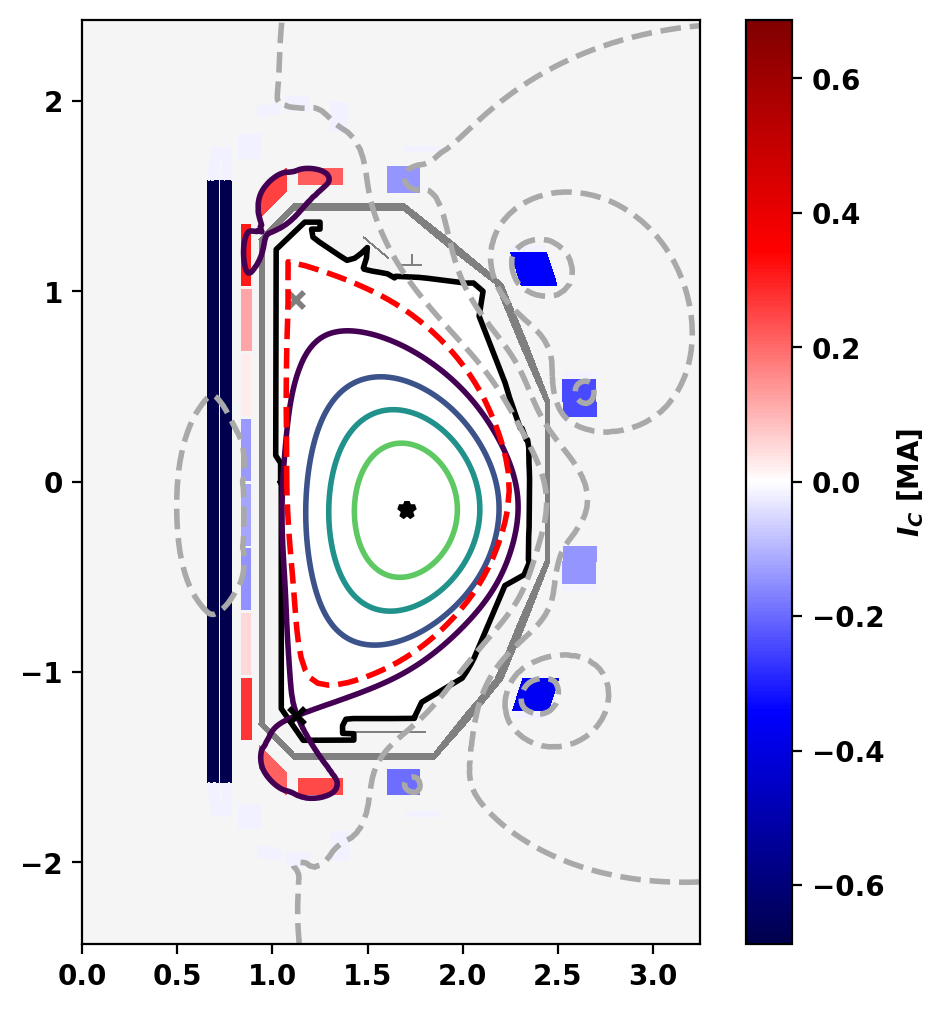

In [15]:
EQ_guess = mygs.copy_eq()
EQ_guess.print_info()
 
print()
print("Coil Currents [MA]:")
coil_currents, _ = EQ_guess.get_coil_currents()
for key, current in coil_currents.items():
    print('  {0:10} {1:10.2F}'.format(key+":",current/1.E6))
 
# Plot first case surfaces
fig, ax = plt.subplots(1,1)
mygs.plot_machine(fig,ax,equilibrium=EQ_guess,coil_colormap='seismic',coil_scale=1.E-6,coil_clabel=r'$I_C$ [MA]',coil_symmap=True)
mygs.plot_psi(fig,ax,equilibrium=EQ_guess,plasma_nlevels=5,vacuum_nlevels=5)

lcfs = eqdsk['rzout']
ax.plot(lcfs[:,0], lcfs[:,1], color='red', linestyle='--')

### Plot starting error

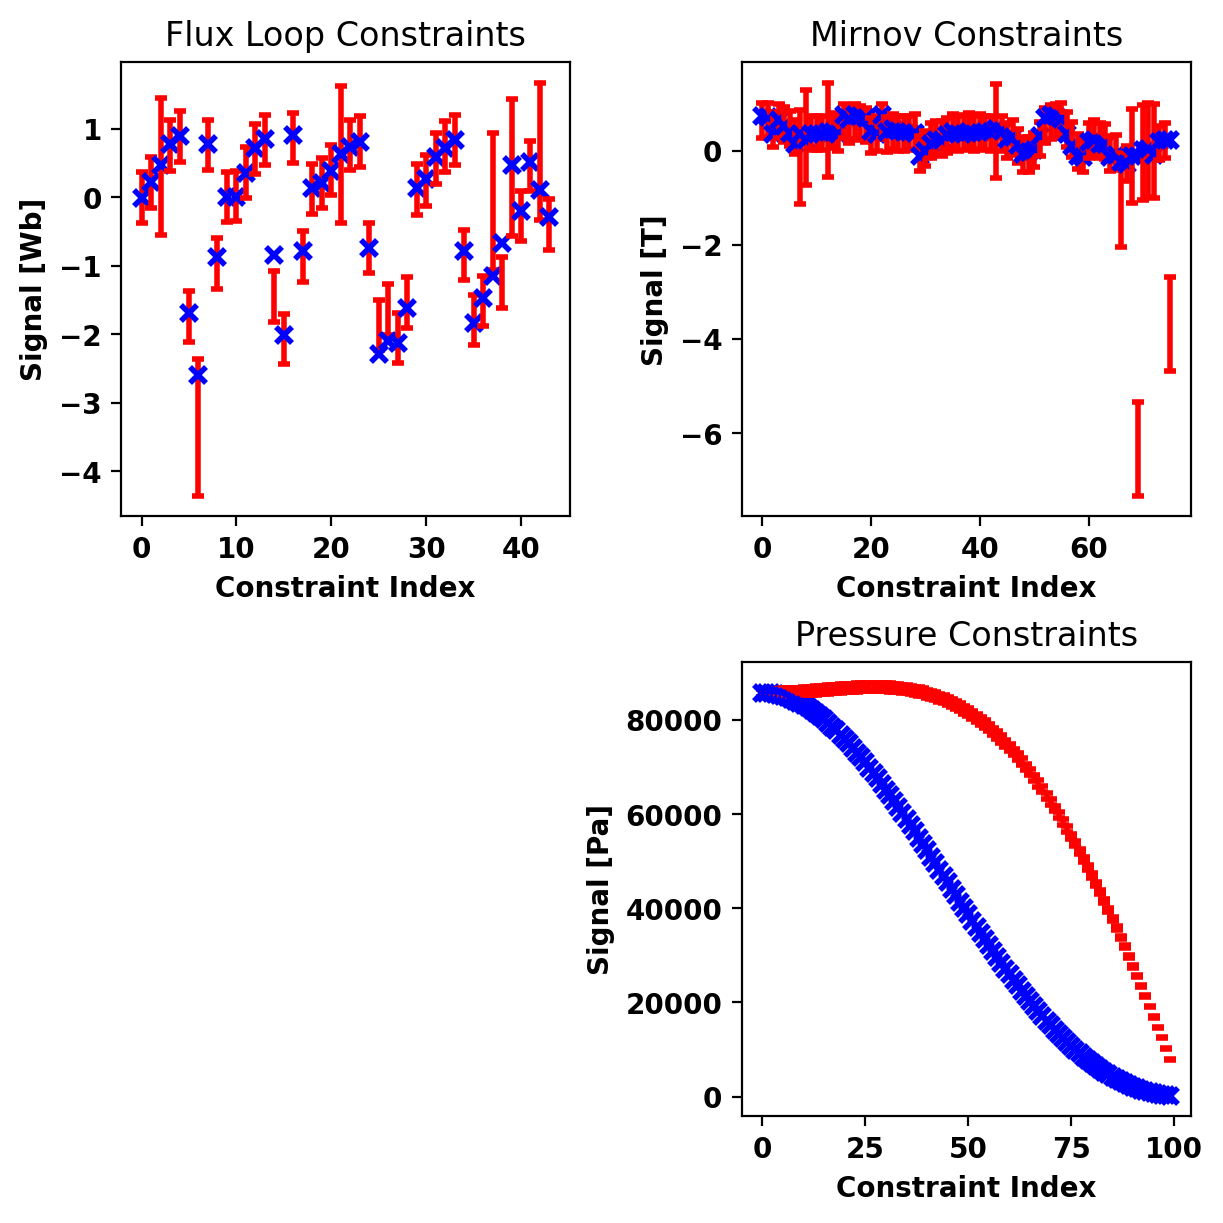

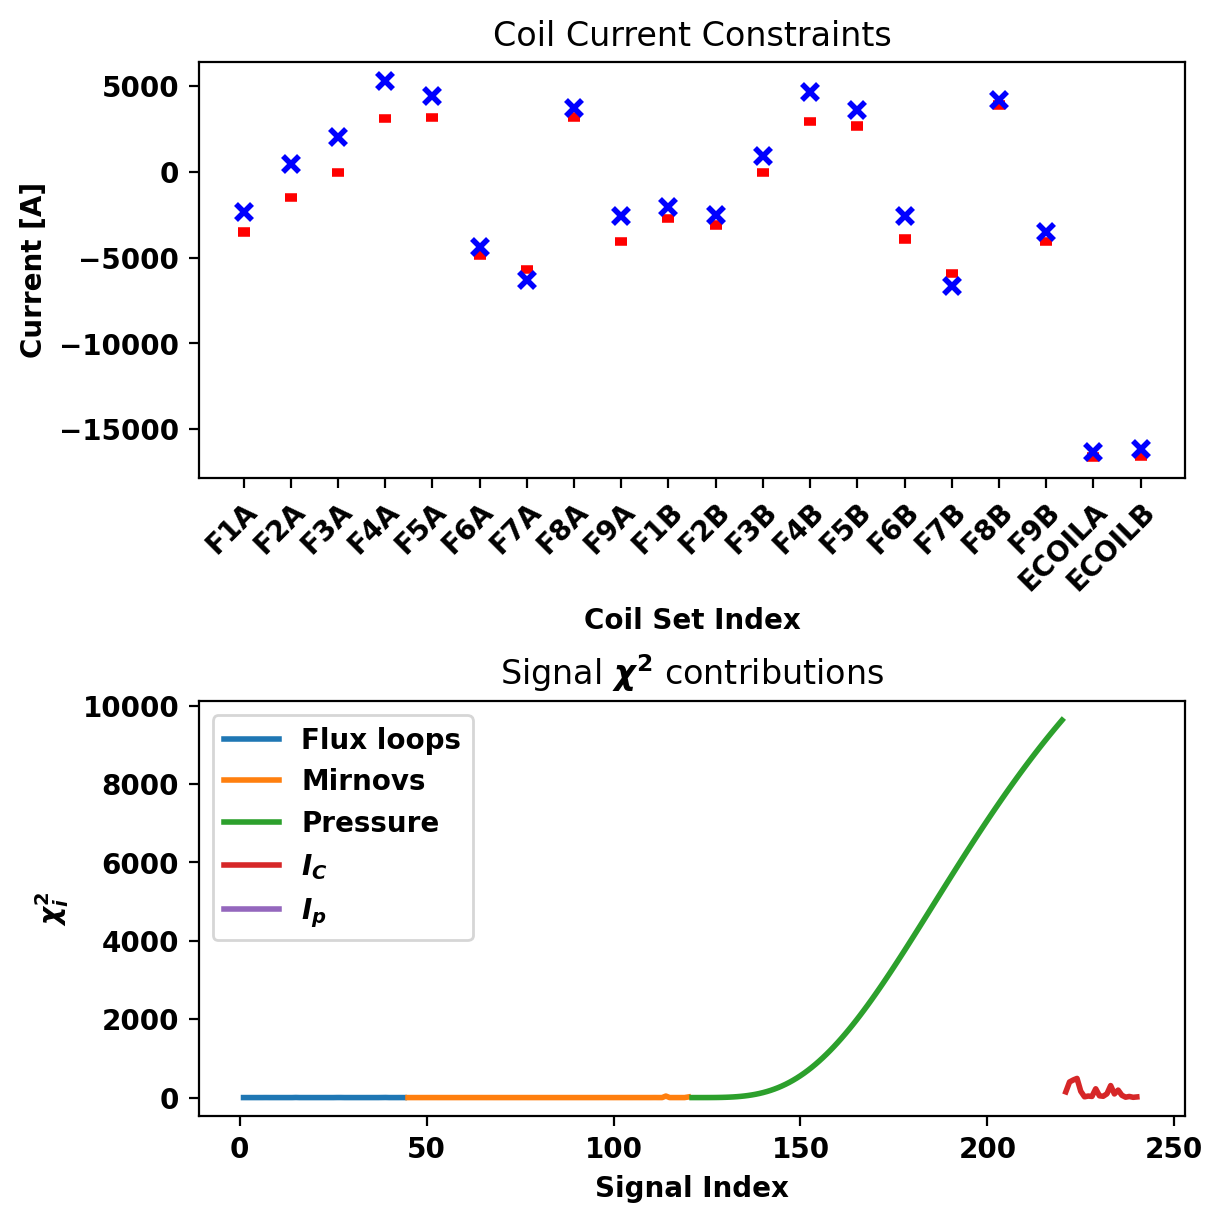

In [16]:
myrecon.setup_constraints()
 
fig, ax = plt.subplots(2,2,constrained_layout=True)
fig2, (coil_ax, chi_ax) = plt.subplots(2,1,constrained_layout=True)
myrecon.plot_error(ax.flatten(),coil_ax=coil_ax,chi_ax=chi_ax)

## Refine Reconstruction Using Nonlinear Optimization
We now refine the reconstruction by applying a general nonlinear optimization approach over the inner diagnostic-constrained nonlinear solve. The \ref OpenFUSIONToolkit.TokaMaker.reconstruction.reconstruction "TokaMaker reconstruction object" has several helper functions to support this for optimization approaches that use callable error and Jacobian functions as shown below for the [scipy.optimize.least_squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html) method, which uses both callable functions with a Levenberg–Marquardt algorithm.

**Note:** The \ref OpenFUSIONToolkit.TokaMaker.reconstruction.reconstruction.opt_error "opt_error()" and \ref OpenFUSIONToolkit.TokaMaker.reconstruction.reconstruction.opt_error_jacobian "opt_error_jacobian()" functions both have the same call signature, which includes the DoF vector, reconstruction object, and a logical flag that should be set `False` in arguments passed to the optimizer.

In [17]:
mygs.settings.pm=False
mygs.update_settings()
 
# Configure reconstruction settings
myrecon.settings.fitF = False
myrecon.settings.fitP = False
myrecon.settings.fit_Pscale = True
myrecon.settings.fit_FFPscale = True
myrecon.settings.fitR0 = False
myrecon.settings.fitZ0 = False
myrecon.settings.fixedCentering = False
myrecon.settings.dx = 1.E-2
 
# Set targets for inner solve
mygs.set_targets(Ip=Ip_target, pax=eqdsk['pres'][0])
mygs.settings.ffp_target_weight=1.0/(0.01*Ip_target*mu0)
dflux = mygs.get_stats()['dflux']
mygs.settings.pp_target_weight=10.0/(dflux)

x0_nl, err_in = myrecon.setup_get_opt()

opt_result = least_squares(myrecon.opt_error, x0_nl, jac=myrecon.opt_error_jacobian, method='lm', ftol=1.E-8, args=(myrecon,False))

print()
print(opt_result)
 
mygs.settings.pm=True
mygs.update_settings()

chi_rms = 3.8319E+01; chi_max = 9.8117E+01
chi_rms = 3.8354E+01; chi_max = 9.8196E+01
chi_rms = 3.8354E+01; chi_max = 9.8196E+01
chi_rms = 3.8354E+01; chi_max = 9.8196E+01
chi_rms = 3.8354E+01; chi_max = 9.8196E+01
chi_rms = 3.8354E+01; chi_max = 9.8197E+01
chi_rms = 3.8354E+01; chi_max = 9.8197E+01
chi_rms = 3.8354E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8197E+01
chi_rms = 3.8355E+01; chi_max = 9.8198E+01

     message: `xtol` termination condition is satisfied.
     success: True
      status: 3
         fun: [ 1.588e-02 -3.566e-02 ...  3.983e+00  4.743e-01]
           x: [ 4.993e-01]

### Plot final reconstruction error

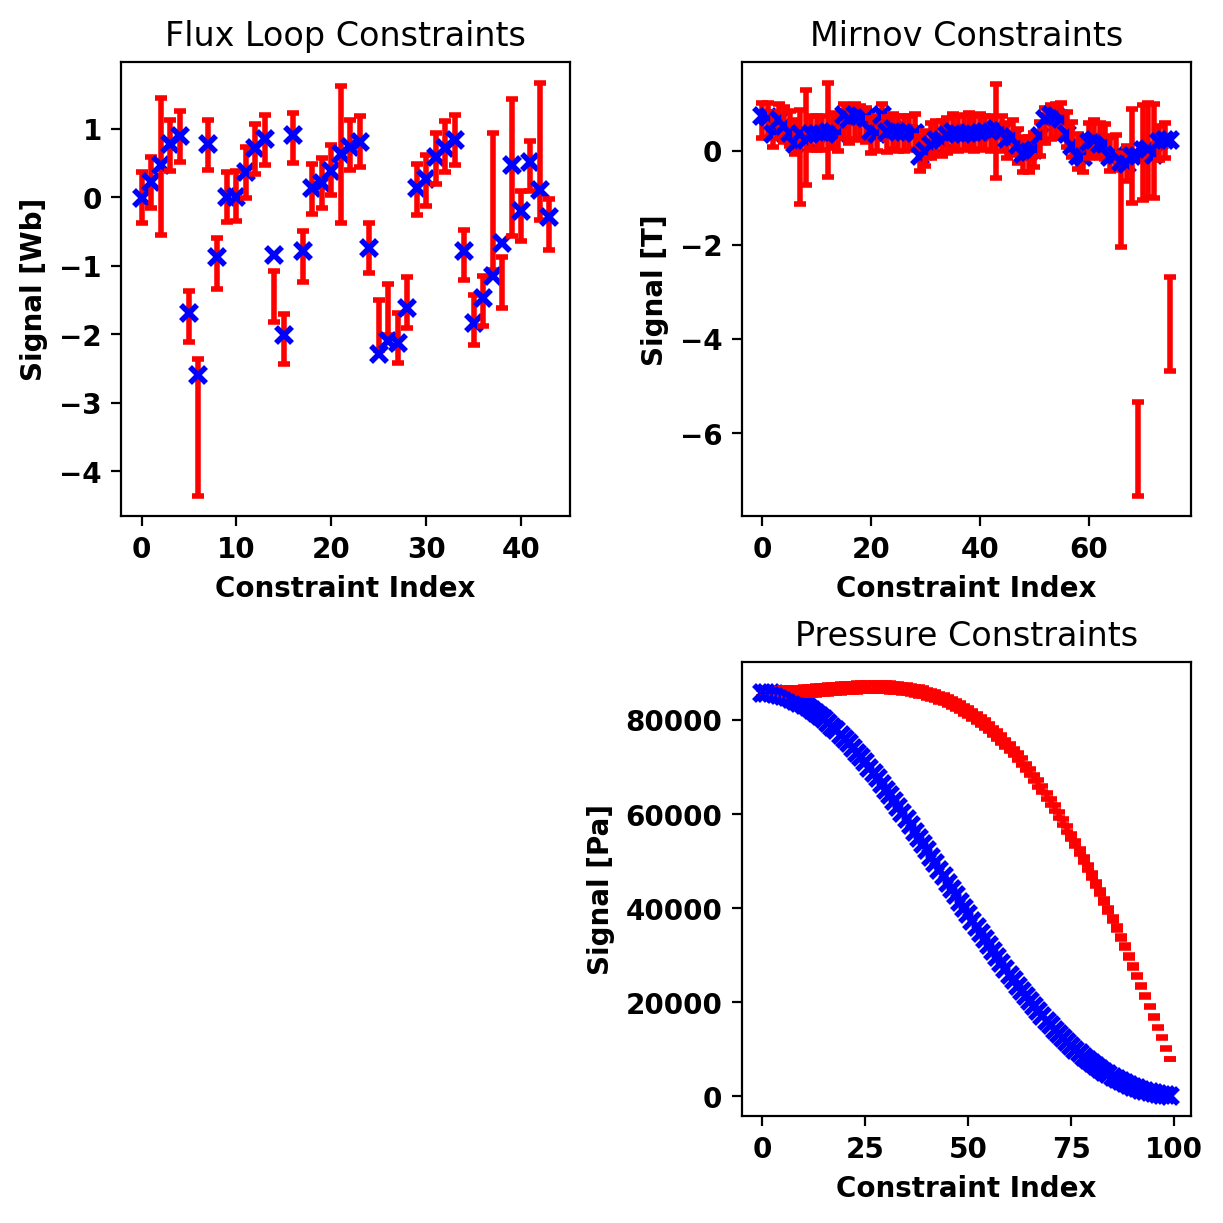

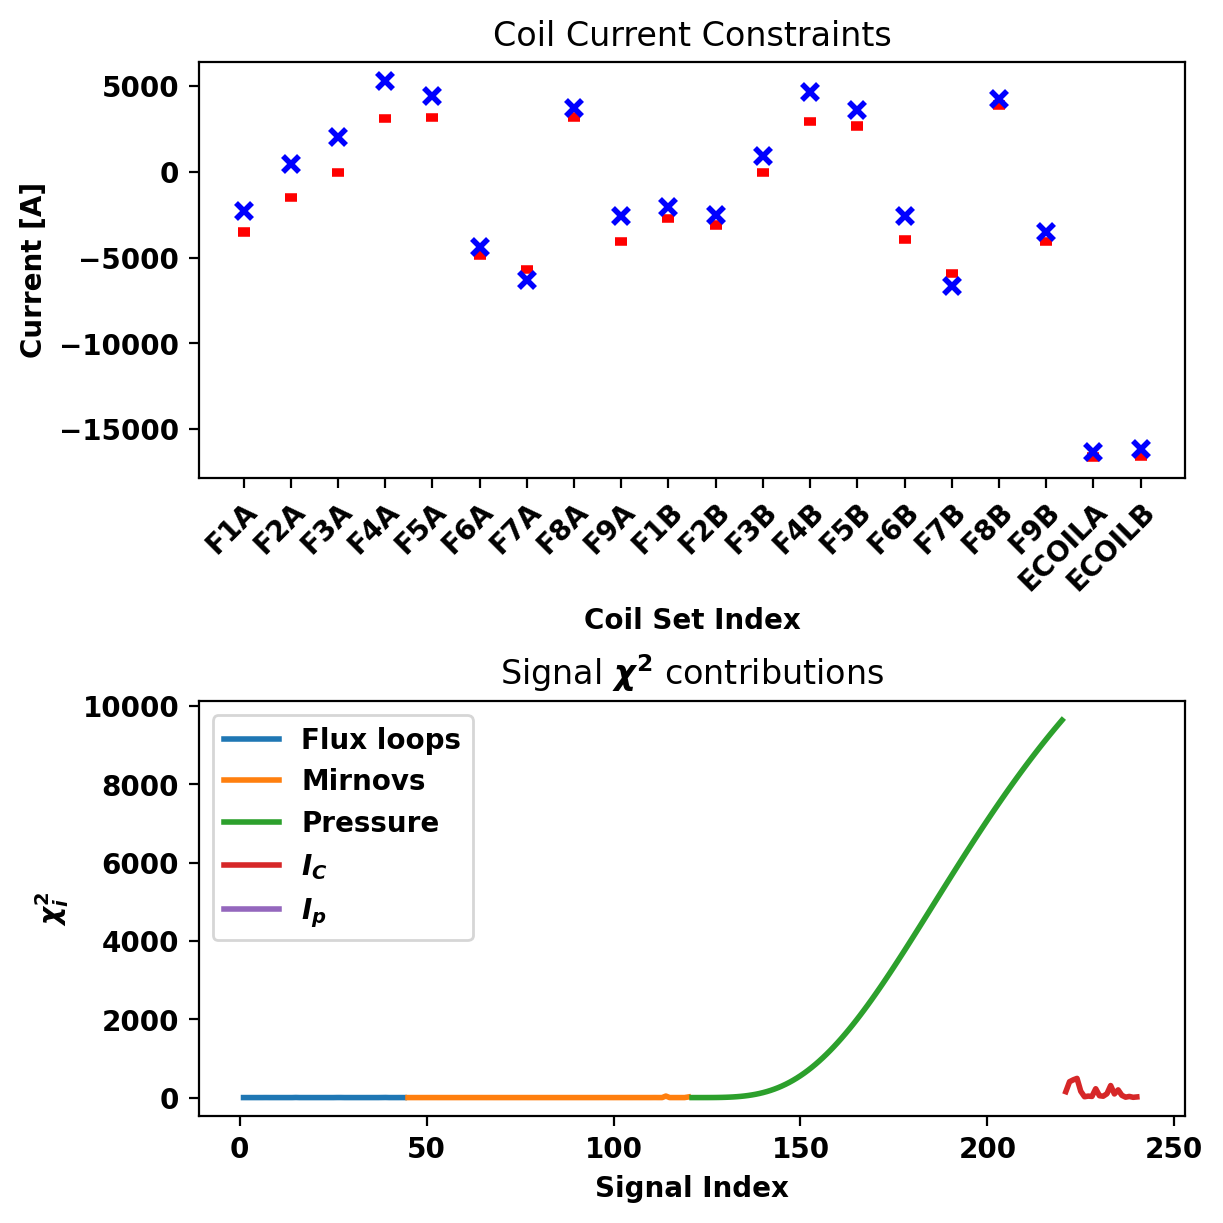

In [18]:
fig, ax = plt.subplots(2,2,constrained_layout=True)
fig2, (coil_ax, chi_ax) = plt.subplots(2,1,constrained_layout=True)
myrecon.plot_error(ax.flatten(),coil_ax=coil_ax,chi_ax=chi_ax)

### Plot final reconstructed solution

Equilibrium Statistics:
  Topology                =   Diverted
  Toroidal Current [A]    =    1.7720E+06
  Current Centroid [m]    =    1.632 -0.157
  Magnetic Axis [m]       =    1.708 -0.151
  Elongation              =    1.631 (U:  1.517, L:  1.745)
  Triangularity           =    0.667 (U:  0.446, L:  0.888)
  Plasma Volume [m^3]     =   18.481
  q_0, q_95               =   -0.919 -3.311
  Plasma Pressure [Pa]    =   Axis:  8.5621E+04, Peak:  8.5621E+04
  Stored Energy [J]       =    6.0056E+05
  <Beta_pol> [%]          =   30.7180
  <Beta_tor> [%]          =    1.1798
  <Beta_n>   [%]          =    0.8858
  Diamagnetic flux [Wb]   =   -5.7157E-02
  Toroidal flux [Wb]      =   -4.3982E+00
  l_i                     =    1.1065

Coil Currents [MA]:
  Name       Reconstructed Ground Truth Error from target
  F1A:            -0.00      -0.00      34.32
  F2A:             0.00      -0.00     131.16
  F3A:             0.00      -0.00    4492.61
  F4A:             0.01       0.00      69.9

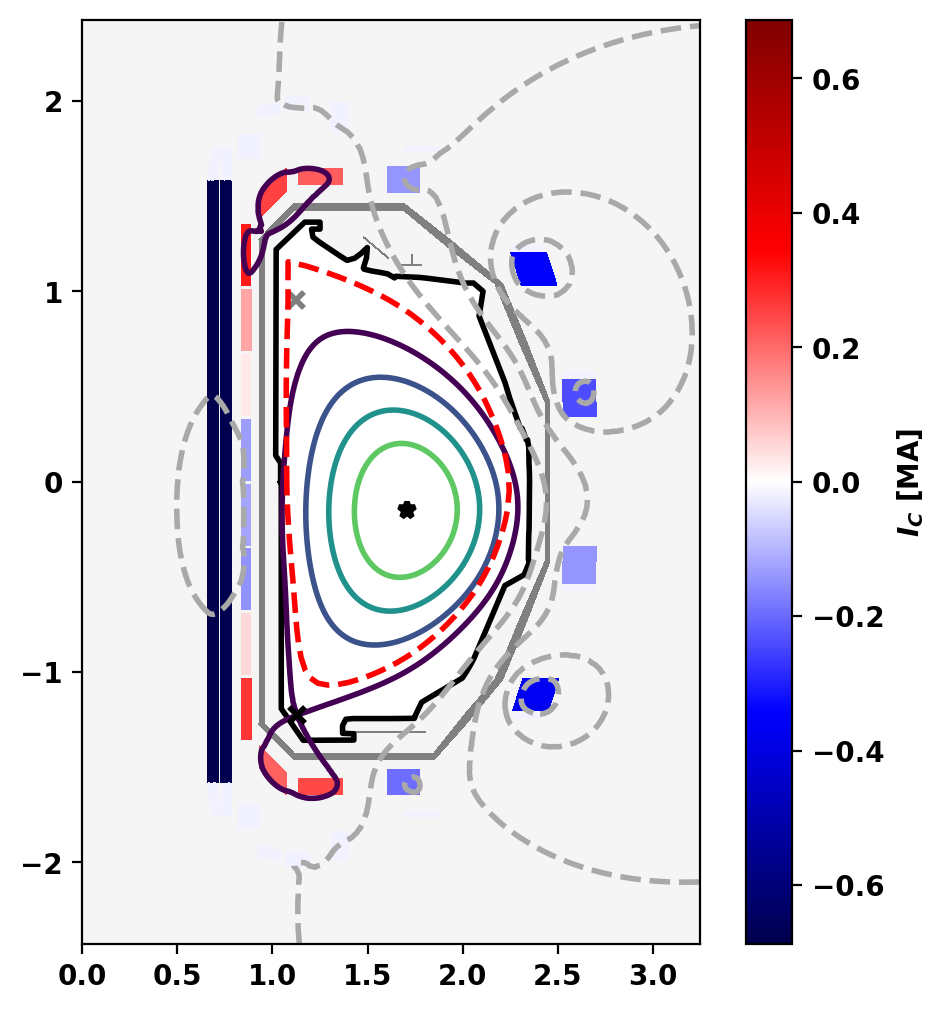

In [19]:
mygs.print_info()

print()
print("Coil Currents [MA]:")
print("  {0:10} {1:10} {2:10} {3:10}".format("Name", "Reconstructed", "Ground Truth", "Error from target"))
coil_ref = target_currents
coil_currents, _ = mygs.get_coil_currents()
for key, current in coil_currents.items():
    if key == 'VS':
        print('  {0:10} {1:10.2F} {2:10.2F} {3:10.2F}'.format(key+":",current/1.E3,coil_ref[key]/1.E3,100.0*(current-coil_ref[key])/abs(coil_ref[key])))
    else:
        print('  {0:10} {1:10.2F} {2:10.2F} {3:10.2F}'.format(key+":",current/1.E6,coil_ref[key]/1.E6,100.0*(current-coil_ref[key])/abs(coil_ref[key])))

# Plot first case surfaces
fig, ax = plt.subplots(1,1)
mygs.plot_machine(fig,ax,coil_colormap='seismic',coil_scale=1.E-6,coil_clabel=r'$I_C$ [MA]',coil_symmap=True)
mygs.plot_psi(fig,ax,plasma_nlevels=5,vacuum_nlevels=5)
ax.plot(lcfs[:,0], lcfs[:,1], color='red', linestyle='--')

### Plot Current Density
Here we plot current density in the reactor.

Starting CG solver
     0  0.000000E+00  0.000000E+00  1.358755E-01
     1 -3.712117E+01  6.570473E+02  3.040715E-02  4.627848E-05
     2 -3.941307E+01  7.316501E+02  1.489449E-02  2.035739E-05
     3 -3.971253E+01  7.609555E+02  5.329933E-03  7.004264E-06
     4 -3.973828E+01  7.643057E+02  2.023992E-03  2.648145E-06
     5 -3.974202E+01  7.652486E+02  7.777403E-04  1.016324E-06
     6 -3.974264E+01  7.646636E+02  2.909920E-04  3.805490E-07
     7 -3.974273E+01  7.643209E+02  1.024442E-04  1.340329E-07
     8 -3.974274E+01  7.642420E+02  3.647421E-05  4.772599E-08
     9 -3.974274E+01  7.642298E+02  1.515397E-05  1.982907E-08
    10 -3.974274E+01  7.642304E+02  6.469037E-06  8.464773E-09
    20 -3.974274E+01  7.642347E+02  4.113321E-10  5.382274E-13


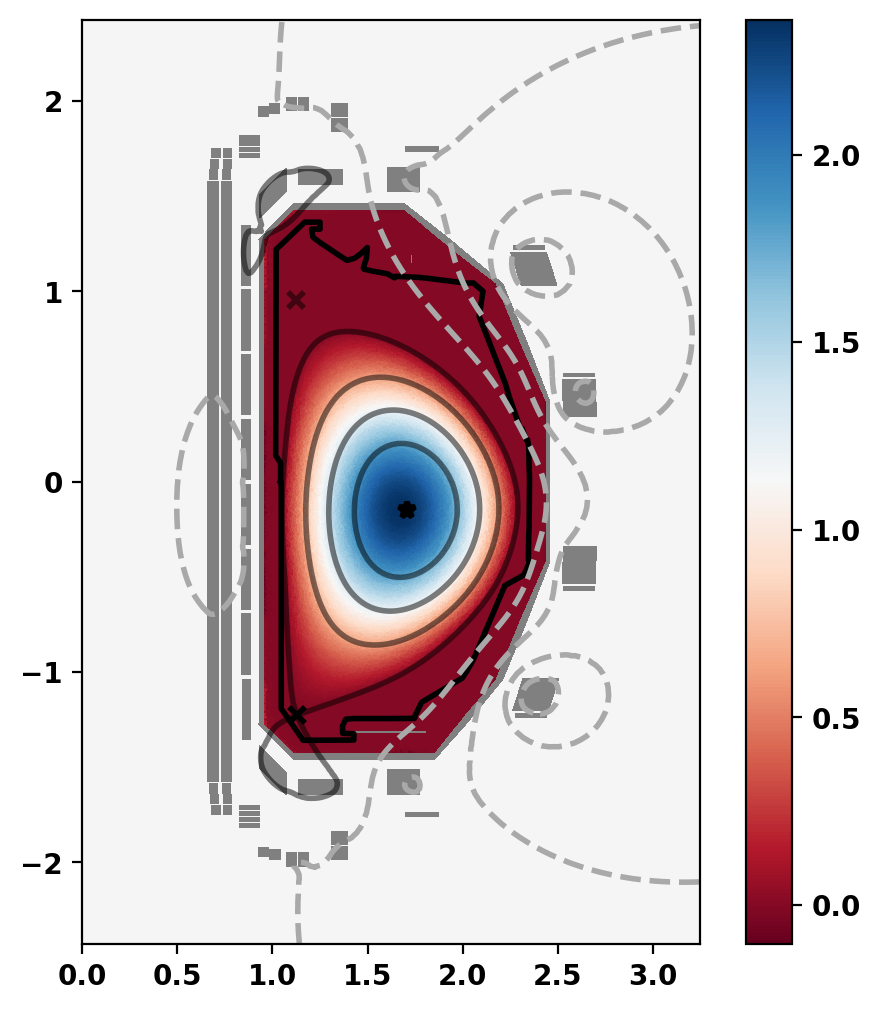

In [20]:
from matplotlib.colors import ListedColormap

fig, ax = plt.subplots()
cmap = ListedColormap([[0.0, 0.0, 0.0, 0.5]])

mygs.plot_machine(fig,ax,coil_clabel=None)
mygs.plot_psi(fig,ax,plasma_nlevels=5,vacuum_nlevels=5, plasma_colormap=cmap)
mygs.plot_current_density(fig, ax, cmap='RdBu')

# Show the plot
plt.show()

### Plot Current Density in Divertor Region
Here we provide a zoomed-in view of the previous plot, focusing on the divertor region.

Starting CG solver
     0  0.000000E+00  0.000000E+00  1.358755E-01
     1 -3.712117E+01  6.570473E+02  3.040715E-02  4.627848E-05
     2 -3.941307E+01  7.316501E+02  1.489449E-02  2.035739E-05
     3 -3.971253E+01  7.609555E+02  5.329933E-03  7.004264E-06
     4 -3.973828E+01  7.643057E+02  2.023992E-03  2.648145E-06
     5 -3.974202E+01  7.652486E+02  7.777403E-04  1.016324E-06
     6 -3.974264E+01  7.646636E+02  2.909920E-04  3.805490E-07
     7 -3.974273E+01  7.643209E+02  1.024442E-04  1.340329E-07
     8 -3.974274E+01  7.642420E+02  3.647421E-05  4.772599E-08
     9 -3.974274E+01  7.642298E+02  1.515397E-05  1.982907E-08
    10 -3.974274E+01  7.642304E+02  6.469037E-06  8.464773E-09
    20 -3.974274E+01  7.642347E+02  4.113321E-10  5.382274E-13


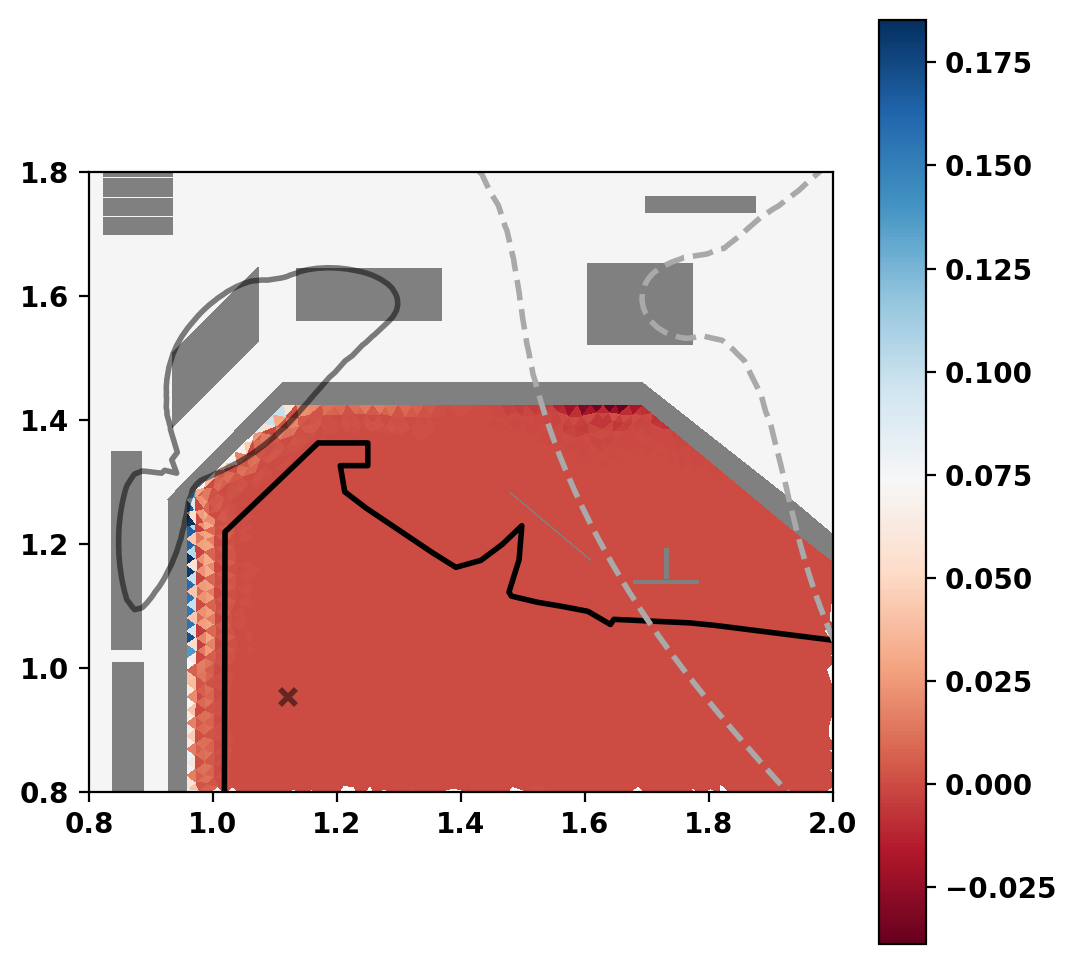

In [21]:
fig, ax = plt.subplots()
cmap = ListedColormap([[0.0, 0.0, 0.0, 0.5]])

mygs.plot_machine(fig,ax,coil_clabel=None)
mygs.plot_psi(fig,ax,plasma_nlevels=5,vacuum_nlevels=5, plasma_colormap=cmap)
mygs.plot_current_density(fig, ax, window=[0.8, 2.0, 0.8, 1.8], cmap='RdBu')

# Show the plot
plt.show()

### Get Strike Points
We can now calculate strike points that occur on the top of the machine using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.get_strike_points "get_strike_points()". Note that positive SOL currents move the strike point left while negative currents move it right (to see this effect, toggle the f_SOL_sign variable in FF' and P' profiles section).

=== Strike Point Coords ===


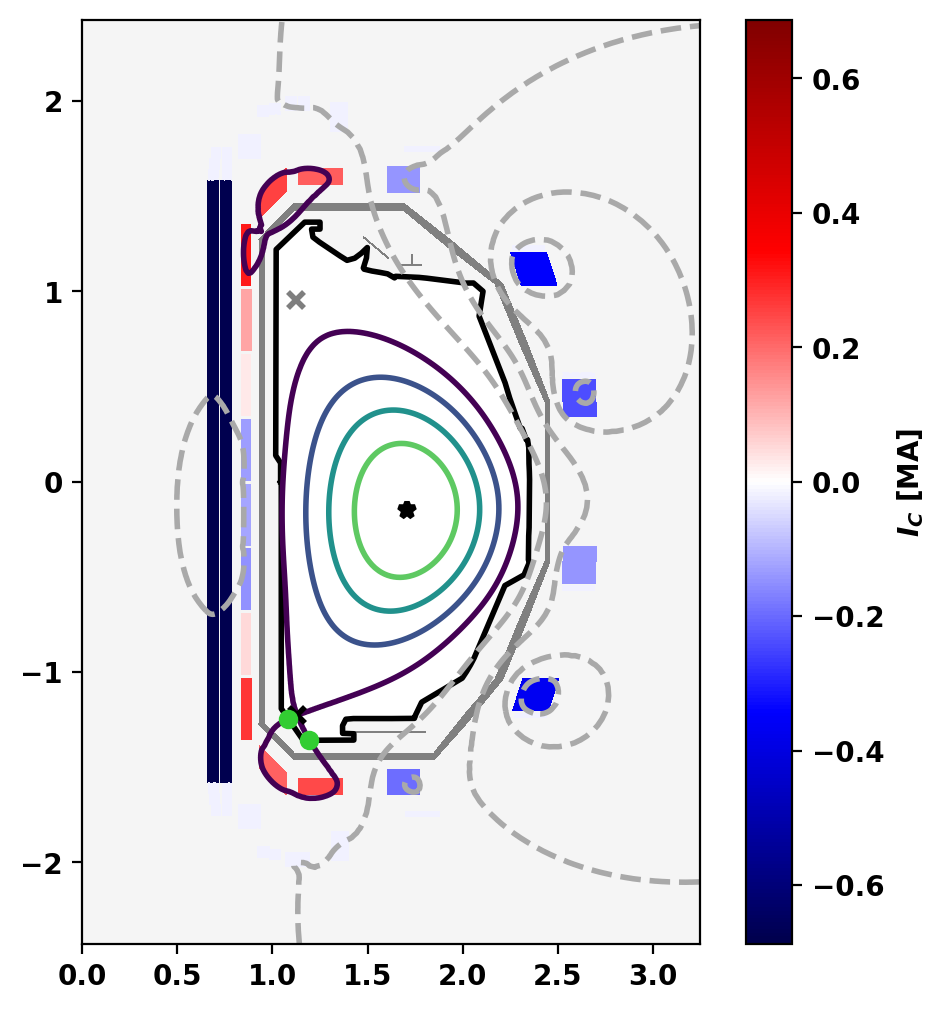

In [22]:
# Plot Psi
fig, ax = plt.subplots()
mygs.plot_machine(fig,ax,coil_colormap='seismic',coil_scale=1.E-6,coil_clabel=r'$I_C$ [MA]',coil_symmap=True)
mygs.plot_psi(fig,ax,plasma_nlevels=5,vacuum_nlevels=5)

strike_pts = mygs.get_strike_points()
strike_pts_r = [sp[0] for sp in strike_pts]
strike_pts_z = [sp[1] for sp in strike_pts]
ax.scatter(strike_pts_r, strike_pts_z, color='limegreen', zorder=10)

print('=== Strike Point Coords ===')
for i, r in enumerate(strike_pts_r):
    if strike_pts_z[i] > 0:
        print(f'R={r}')

plt.show()